# Augmentation — TODO
Chưa thực hiện thí nghiệm. Giữ nguyên split seed 42; chỉ so sánh trên validation.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()

while not (ROOT / "source" / "config.py").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Project root not found")

    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Project root:", ROOT)

Project root: /home/kjwyy/Documents/code/IMGproccess/BT-TH/ImageProcessing_Lab02


In [2]:
import numpy as np

image = np.array([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
], dtype=np.uint8)

image = image[:, :, None]

print(image[:, :, 0])

[[1 2 3]
 [4 5 6]
 [7 8 9]]


In [3]:
from source.augmentation import horizontal_flip,random_horizontal_flip,rotate_image,random_rotation

result = horizontal_flip(image)

print(result[:, :, 0])

[[3 2 1]
 [6 5 4]
 [9 8 7]]


In [4]:
assert np.array_equal(
    random_horizontal_flip(image, probability=0),
    image
)

assert np.array_equal(
    random_horizontal_flip(image, probability=1),
    horizontal_flip(image)
)

print("Random Horizontal Flip: PASS")

Random Horizontal Flip: PASS


In [5]:
import cv2
import numpy as np

from source.augmentation import (
    rotate_image,
    random_rotation
)

image_path = ROOT / "data/raw/horses/train__horse01-0.png"

image = cv2.imread(
    str(image_path),
    cv2.IMREAD_UNCHANGED
)

assert image is not None

print(image.shape)

(300, 300, 4)


In [6]:
result = rotate_image(image, 0)

assert np.array_equal(result, image)

print("Zero rotation: PASS")

Zero rotation: PASS


In [7]:
result = rotate_image(image, 15)

assert result.shape == image.shape
assert result.dtype == image.dtype
assert np.all(result[:, :, 3] == 255)

print("Rotation properties: PASS")

Rotation properties: PASS


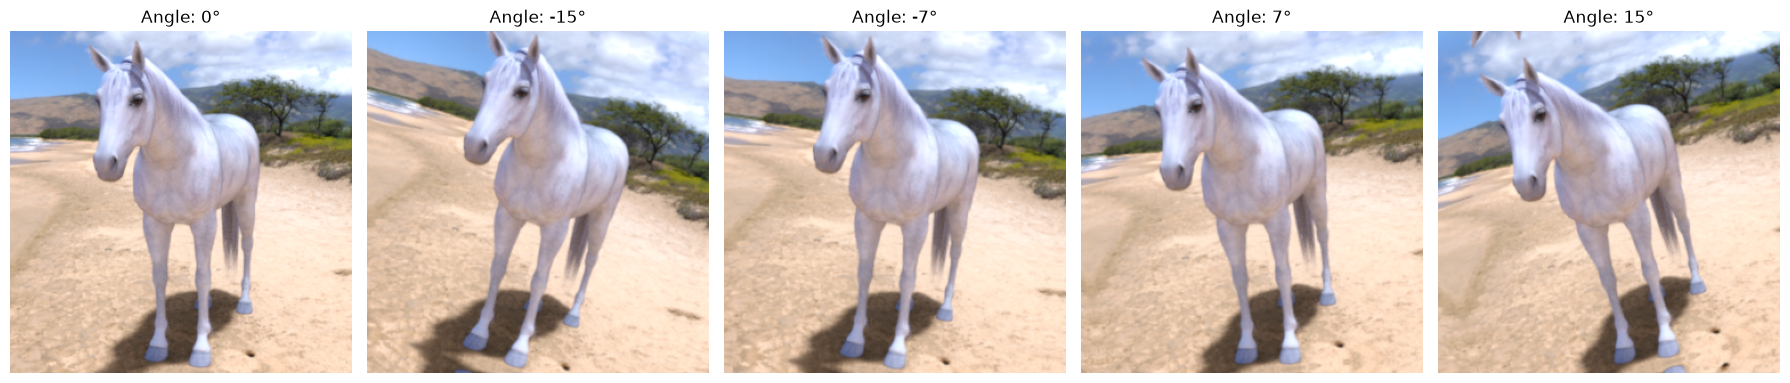

In [8]:
import matplotlib.pyplot as plt

angles = [0, -15, -7, 7, 15]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, angle in zip(axes, angles):

    result = rotate_image(image, angle)

    result = cv2.cvtColor(
        result,
        cv2.COLOR_BGRA2RGB
    )

    ax.imshow(result)
    ax.set_title(f"Angle: {angle}°")
    ax.axis("off")

plt.tight_layout()

plt.show()

In [9]:
from source.config import CONFIG
from source.augmentation import build_augmentation
import torch
import cv2
import random

image_path = CONFIG.raw_dir / "horses/train__horse01-0.png"

image = cv2.imread(
    str(image_path),
    cv2.IMREAD_UNCHANGED
)

assert image is not None

transform = build_augmentation(CONFIG)

tensor = transform(image)

print("Shape:", tensor.shape)
print("Dtype:", tensor.dtype)
print("Min:", tensor.min().item())
print("Max:", tensor.max().item())

Shape: torch.Size([3, 64, 64])
Dtype: torch.float32
Min: 0.08627451211214066
Max: 1.0


In [10]:
import cv2
import torch
import numpy as np
import pandas as pd
import random

from source.config import CONFIG
from source.augmentation import build_augmentation
from source.preprocessing import build_preprocessing
from source.dataset import build_loaders

df = pd.read_csv(CONFIG.splits_dir / "train.csv")

image_path = CONFIG.root / df.iloc[0]["image_path"]

image = cv2.imread(
    str(image_path),
    cv2.IMREAD_UNCHANGED
)

assert image is not None

print("Original shape:", image.shape)

Original shape: (300, 300, 4)


In [11]:
transform = build_augmentation(CONFIG)

tensor = transform(image)

assert tensor.shape == (3, 64, 64)
assert tensor.dtype == torch.float32
assert tensor.min() >= 0
assert tensor.max() <= 1
assert torch.isfinite(tensor).all()

print("Augmentation Pipeline: PASS")

Augmentation Pipeline: PASS


In [12]:
random.seed(42)
tensor1 = transform(image)

random.seed(42)
tensor2 = transform(image)

assert torch.equal(tensor1, tensor2)

print("Reproducibility: PASS")

Reproducibility: PASS


In [13]:
original = image.copy()

transform(image)

assert np.array_equal(original, image)

print("Non-destructive Transformation: PASS")

Non-destructive Transformation: PASS


In [14]:
random.seed(CONFIG.seed)

train_transform = build_augmentation(CONFIG)

eval_transform = build_preprocessing(
    CONFIG.image_size
)

loaders = build_loaders(
    CONFIG,
    train_transform=train_transform,
    eval_transform=eval_transform
)

In [15]:
for name, loader in loaders.items():

    images, labels = next(iter(loader))

    assert images.shape == (32, 3, 64, 64)
    assert labels.shape == (32, 1)
    assert images.dtype == torch.float32
    assert torch.isfinite(images).all()
    assert images.min() >= 0
    assert images.max() <= 1

    print(f"{name}: PASS")
    print("Images:", images.shape)
    print("Labels:", labels.shape)

train: PASS
Images: torch.Size([32, 3, 64, 64])
Labels: torch.Size([32, 1])
val: PASS
Images: torch.Size([32, 3, 64, 64])
Labels: torch.Size([32, 1])
test: PASS
Images: torch.Size([32, 3, 64, 64])
Labels: torch.Size([32, 1])


In [16]:
for name in ["val", "test"]:

    dataset = loaders[name].dataset

    img1, label1 = dataset[0]
    img2, label2 = dataset[0]

    assert torch.equal(img1, img2)
    assert torch.equal(label1, label2)
    assert dataset.transform is eval_transform

    print(f"{name}: Deterministic - PASS")

val: Deterministic - PASS
test: Deterministic - PASS


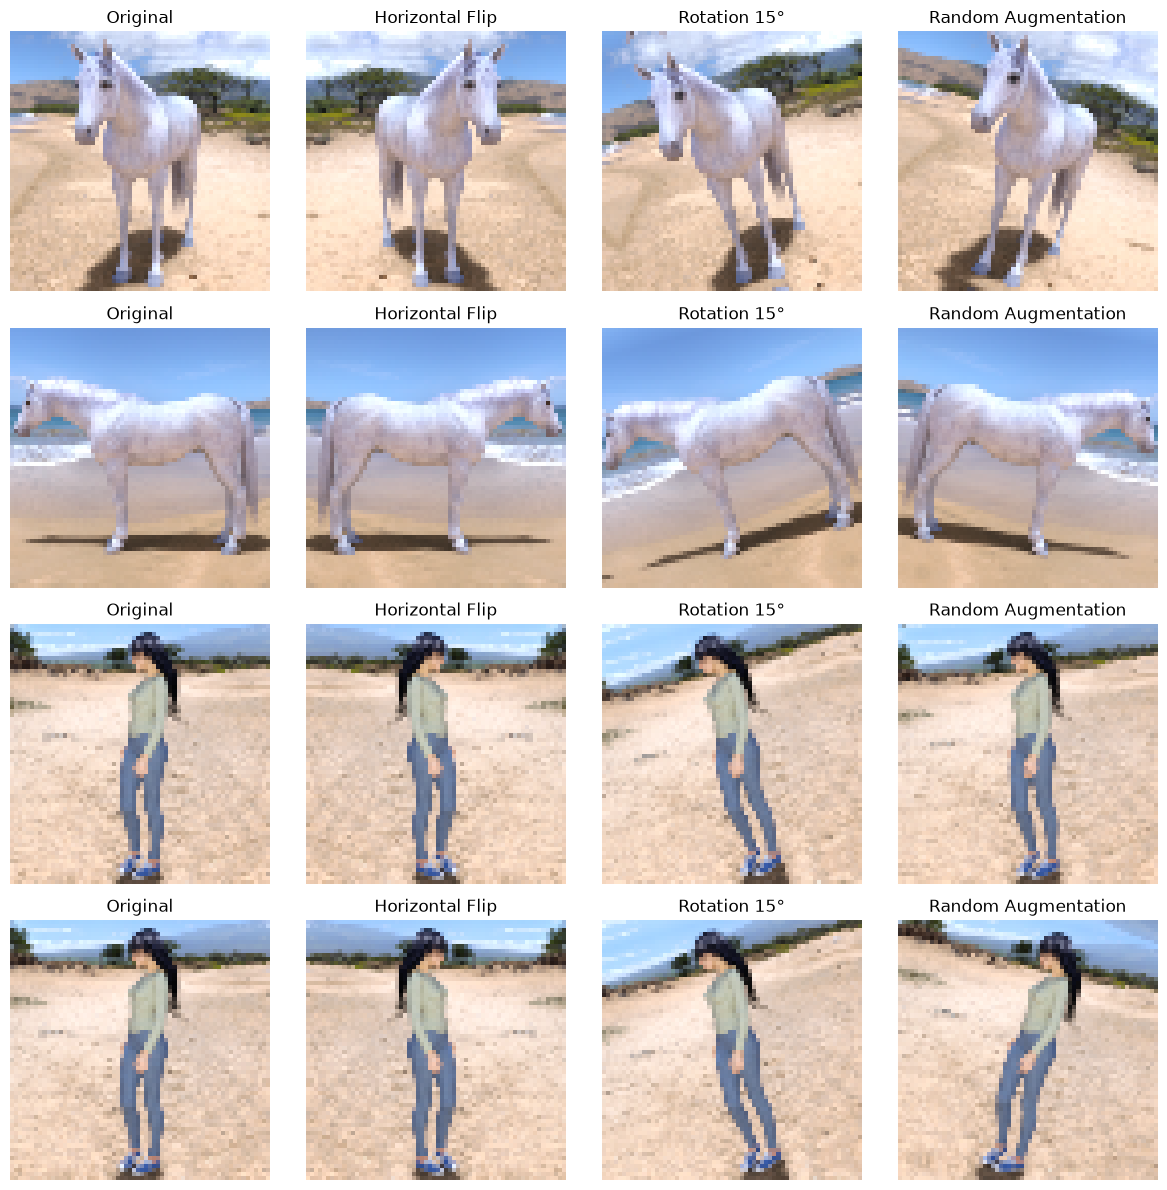

Saved: /home/kjwyy/Documents/code/IMGproccess/BT-TH/ImageProcessing_Lab02/results/figures/augmentation_comparison.png


In [17]:
import matplotlib.pyplot as plt

from source.augmentation import (
    horizontal_flip,
    rotate_image
)

samples = pd.concat([
    df[df["label"] == 0].head(2),
    df[df["label"] == 1].head(2)
])

preprocessing = build_preprocessing(CONFIG.image_size)

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

random.seed(CONFIG.seed)

titles = [
    "Original",
    "Horizontal Flip",
    "Rotation 15°",
    "Random Augmentation"
]

for i, (_, row) in enumerate(samples.iterrows()):

    image = cv2.imread(
        str(CONFIG.root / row["image_path"]),
        cv2.IMREAD_UNCHANGED
    )

    assert image is not None

    variants = [
        preprocessing(image),
        preprocessing(horizontal_flip(image)),
        preprocessing(rotate_image(image, 15)),
        train_transform(image)
    ]

    for j, tensor in enumerate(variants):

        axes[i, j].imshow(tensor.permute(1, 2, 0))

        axes[i, j].set_title(titles[j])
        axes[i, j].axis("off")

plt.tight_layout()

output_path = (
    CONFIG.results_dir
    / "figures"
    / "augmentation_comparison.png"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:", output_path)